# SPI–SPI proof of concept — p90, ordered entries, 2026-10-21

The completed 2026-10-14 extraction (283 SPIs, pyspi computation r9), recomputed with the paper's definition of $z$: every SPI contributes all $M(M-1)$ ordered off-diagonal entries. Embeddings and selected coordinates are refitted under that definition. [proof_p90_261015.ipynb](proof_p90_261015.ipynb) remains the record of the earlier symmetrised view. The figures compare ten generator classes, then four CML regimes, and finally individual SPI–SPI coordinates that distinguish pairs of classes. These embeddings illustrate organisation; they do not establish invariance to channel count or recording length.

In [1]:
from pathlib import Path
import sys, json, os
import matplotlib.pyplot as plt
import numpy as np
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.proof.p90.refresh_proof_figures import (load_bank, embeddings, rank_features, plot_embedding, plot_discriminative)
BANK = Path(os.environ.get('PROOF_REFRESH_BANK', ROOT / 'data/proof/refresh-261014/features.npz'))
OUT = Path(os.environ.get('PROOF_REFRESH_OUTPUT', ROOT / 'results/proof/viewer-261021'))
bank = load_bank(BANK, expected_spis=283, contract='unified_ordered_v3')
OUT.mkdir(parents=True, exist_ok=True)
print(f"{len(bank['y'])} datasets; {len(bank['spi_order'])} SPIs; {bank['X'].shape[1]:,} coordinates ({bank['contract']})")

1080 datasets; 283 SPIs; 39,903 coordinates (unified_ordered_v3)


Feature definition (`unified_ordered_v3`): each SPI contributes its $M(M-1)$ ordered off-diagonal entries $A_{ij}$, $i\neq j$, in one common order, and $z_{ab}$ is the Pearson correlation between the vectors of SPIs $a$ and $b$. This produces $\binom{283}{2}=39\,903$ coordinates.

Both directions of every channel pair are kept. Directed SPIs therefore keep their direction, and antisymmetric SPIs now contribute: phase, PSI, PLI/wPLI and group delay vanish under symmetrisation. Values are assembled exactly from the stored v2 blocks by `mtsspi.spi_spi_contract.unified_from_feature_blocks`:
- pairs involving a directed SPI use the stored ordered-edge correlation;
- undirected pairs, whose MPIs are stored symmetric, take identical values in both views.

Each class has ten instances at every combination of $M\in\{8,16,32\}$ and $T\in\{500,1000,2000\}$. Each panel fits its own unsupervised preprocessing: retain coordinates finite in at least 95% of its datasets, median-impute missing entries, discard near-constant coordinates and centre without variance scaling. PCA provides the linear view. UMAP and t-SNE use the same first 50 PCs: UMAP has 25 neighbours, min_dist=0.25 and spectral initialisation; t-SNE has perplexity 30, PCA initialisation, automatic learning rate, early exaggeration 12 and 1,500 iterations. Both use seed 260924; their neighbourhood parameters are not numerically equivalent. Centring is a design choice, not something mathematically forced by the bounded coordinate range. No class labels enter these fits.

The three VAR models use a fixed ring with literal (self, total-neighbour) coefficients (0.70,0.20), (0.20,0.20), (0.20,0.70). Each neighbour receives half the total weight. These isolate changes in self-dependence and neighbour coupling against the same middle reference. Their spectral radii are 0.90, 0.40 and 0.90; no stability rescaling is applied. Innovation standard deviation is 0.1 and burn-in is 100 steps. This intentionally replaces the old pre-normalisation VAR weights; other generators retain their existing settings.

In [2]:
PROTOCOL = ROOT / 'research/proof/p90/configs/analysis/proof-refresh-261014.yaml'
coords = embeddings(bank, OUT, protocol_path=PROTOCOL)
ranked = rank_features(bank, OUT)

/Users/wedi0306/Code/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Inter-class view. Colours identify classes and remain fixed in subsequent panels. Point size encodes M=8,16,32. Axis coordinates from separate fits are not directly comparable.

PCA is the primary view: its axes have linear loadings and explained variance. This makes them inspectable, not automatically identifiable with physical character; nuisance variation and redundant coordinates can dominate them. t-SNE is the nonlinear companion; UMAP remains an optional comparison below. UMAP and t-SNE axes have no intrinsic meaning; distances between clusters and cluster areas are sensitive to the method and settings. Fixed seeds do not guarantee identical layouts across platforms. Agreement is a visual robustness check, not independent validation. See the original [t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) and [UMAP](https://arxiv.org/abs/1802.03426) papers, and the [initialisation comparison](https://www.nature.com/articles/s41587-020-00809-z).

The coordinate archive also stores PC1/PC2 loadings, feature indices and centring values for each panel, so the linear axes can be traced back to their SPI pairs.

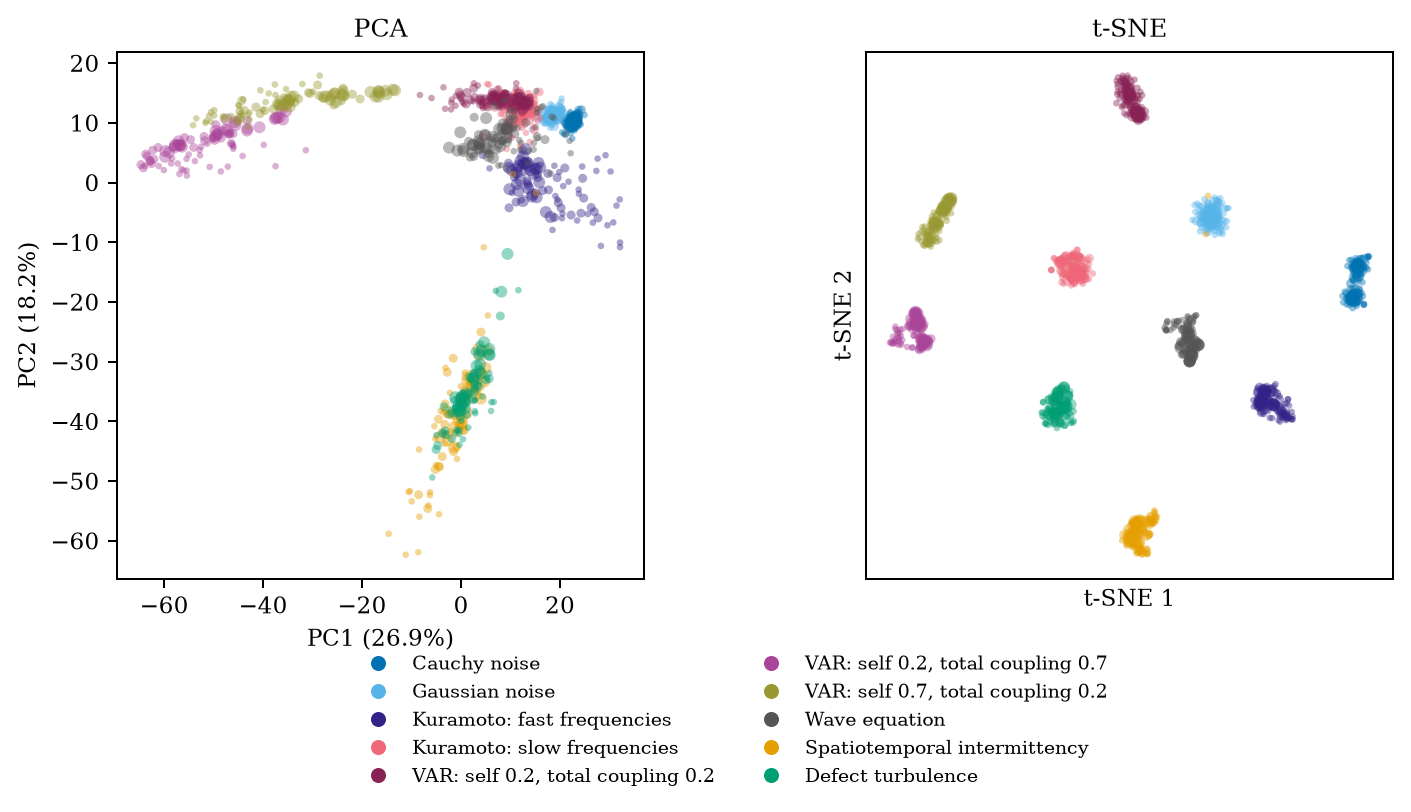

In [3]:
fig = plot_embedding(bank, coords, 'inter', OUT)
plt.show()

Within-CML view: frozen chaos, spatiotemporal intermittency, defect turbulence and fully developed turbulence. The same two bridge classes use the same datasets and colours as the inter-class view.

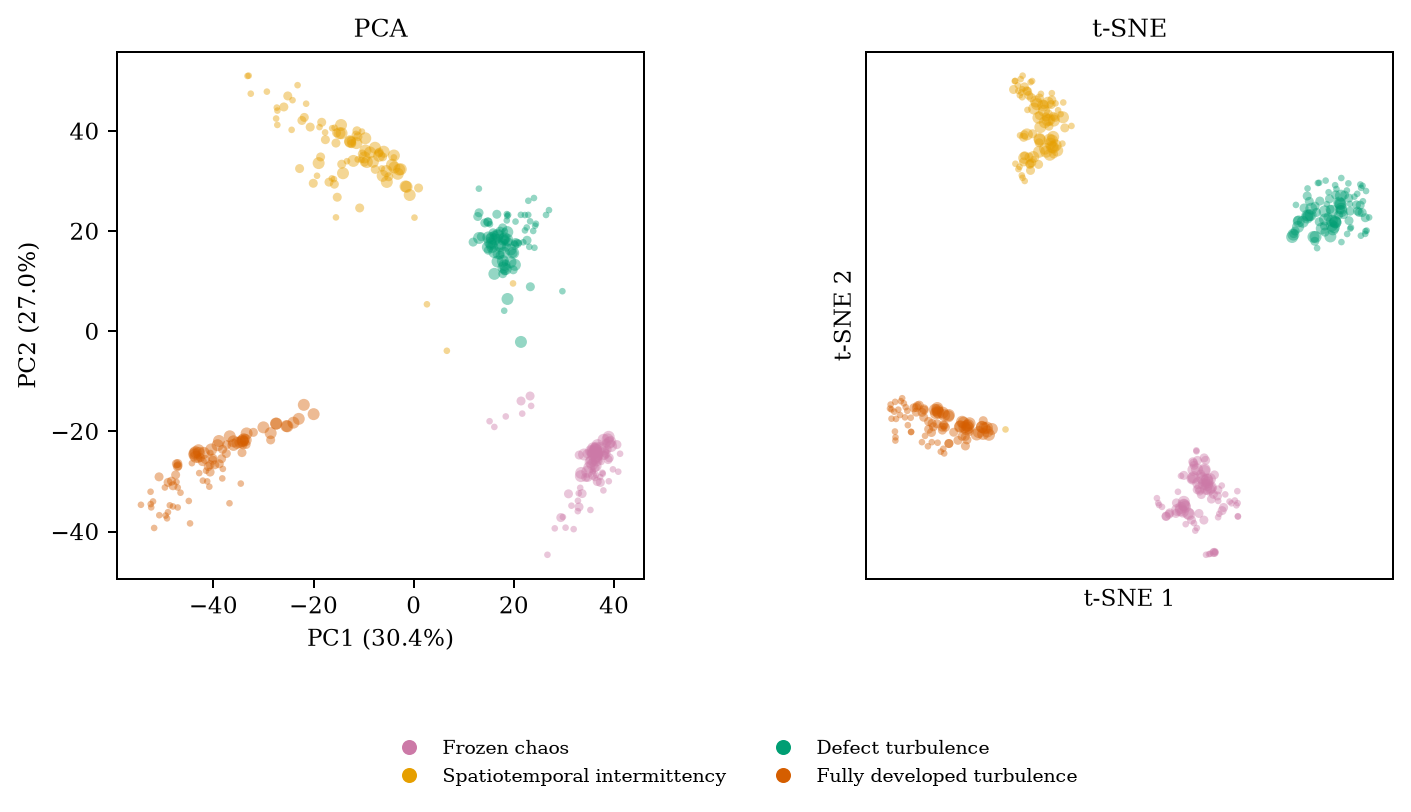

In [4]:
fig = plot_embedding(bank, coords, 'cml', OUT)
plt.show()

Discriminative coordinates. For each class pair, select the SPI pair with greatest training AUC separation using instances 0–5 across all nine M/T cells. The rainclouds display instances 6–9 only (up to 36 datasets/class; undefined coordinate values are omitted), with the training orientation fixed when calculating display AUC. Dots are datasets; density shapes are descriptive; boxes span the 25th–75th percentiles with a median line, and whiskers reach the most extreme observations within 1.5 IQR of the box. Every observation, including boxplot outliers, remains in the scatter. The left-to-right order is scatter, box-and-whisker, density. This limits feature-selection optimism within this rerun, but remains exploratory because these generator families and earlier outcomes have already been inspected. No best-feature significance claim is made.

Each panel is square and boxed. Its y-limits cover the compared classes jointly, with padding; repeated uses of one SPI coordinate share limits, while different coordinates have different limits. Read the numerical ticks when comparing panels: visible separation on a tight scale is not a large absolute change in z. All finite display observations remain visible.

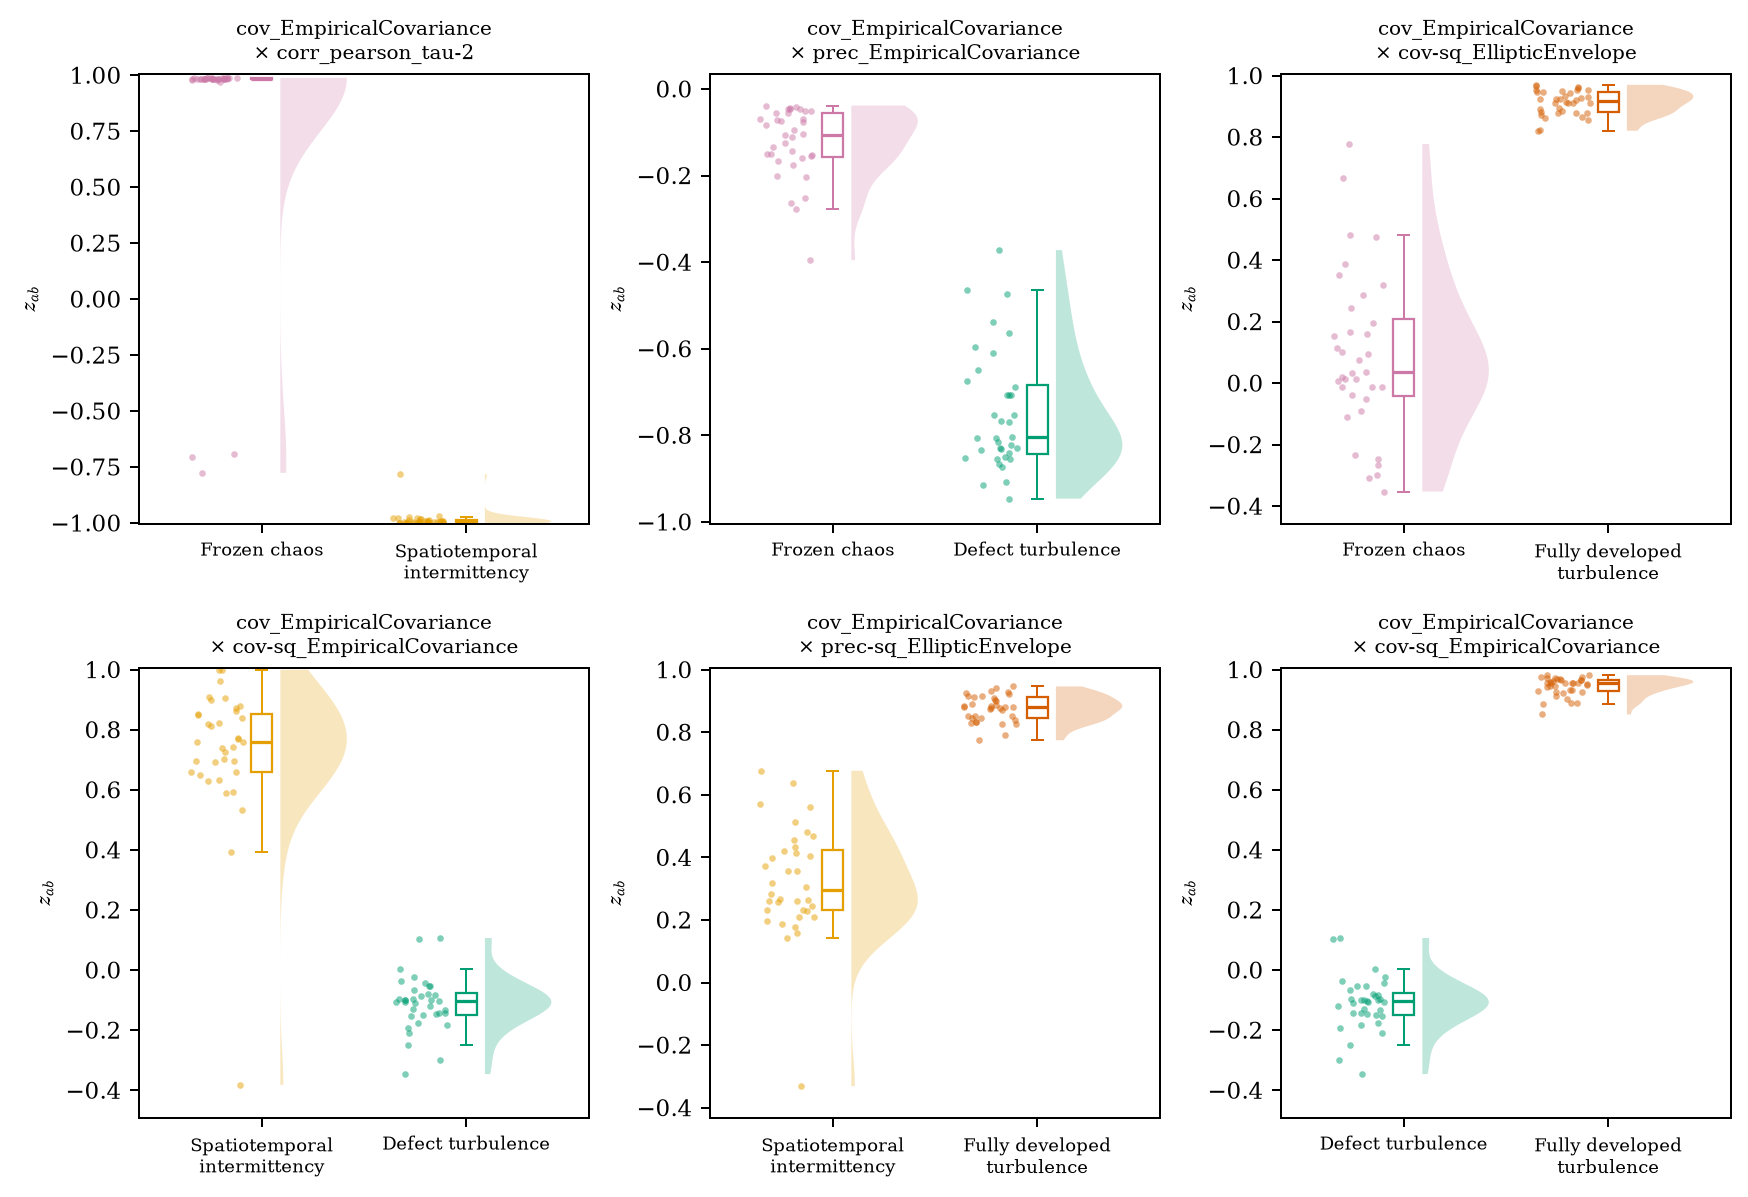

In [5]:
fig = plot_discriminative(bank, ranked, 'cml', OUT)
plt.show()

Coarse contrasts use the same selection rule for Gaussian versus Cauchy noise and all three VAR class pairs. VAR tick labels report self coupling and total neighbour coupling.

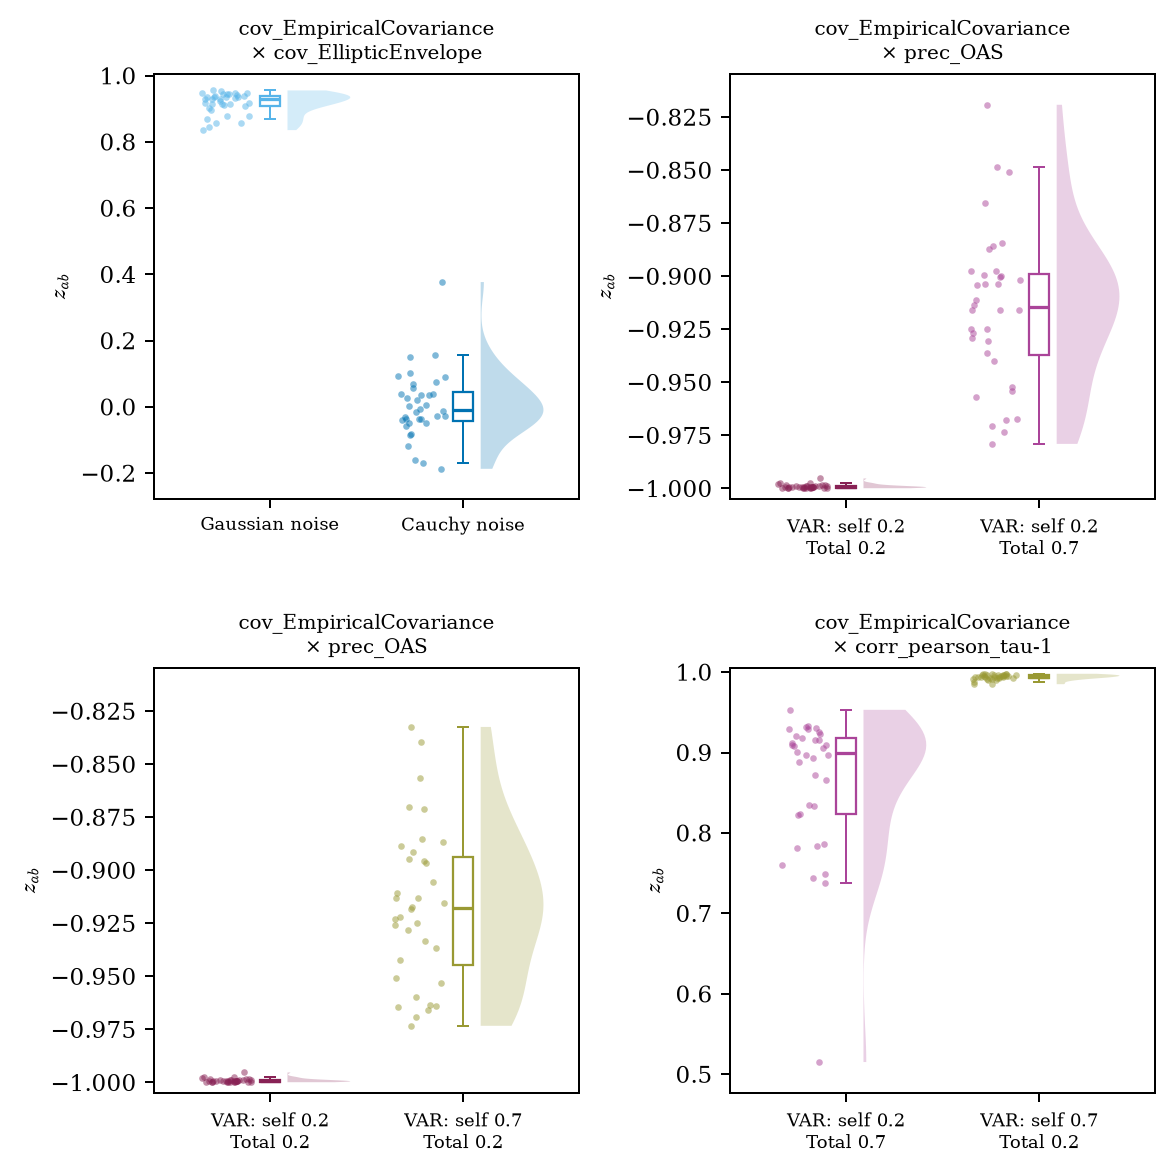

In [6]:
fig = plot_discriminative(bank, ranked, 'coarse', OUT)
plt.show()

Generation and analysis settings (unchanged; only the feature contract differs): `research/proof/p90/configs/analysis/proof-refresh-261014.yaml`. Current pyspi fixes its stochastic estimator seeds. Undefined SPI values remain masked; no historical r7 matrices enter this run. Figures are saved as SVG and PNG.

The generation YAML remains unchanged; compact raincloud layout and box-and-whisker marks are implemented in `research/proof/p90/refresh_proof_figures.py` and `src/mtsspi/figures.py`.

Optional UMAP comparison, using the same saved preprocessing and fitted coordinates. Enable the flag to display it; the main figures prioritise PCA and t-SNE.

In [7]:
SHOW_UMAP = False
if SHOW_UMAP:
    for panel in ['inter', 'cml']:
        fig = plot_embedding(bank, coords, panel, OUT, methods=['umap'])
        plt.show()

## Proof figure, 2026-10-29

This figure replaces the 16 October composite, which had inter-class and within-CML embeddings. It shows one t-SNE of nine classes above four class contrasts. Settings are frozen in `research/proof/p90/configs/analysis/proof-figure-261029.yaml`. The embedding is refitted on the displayed recordings only, using the preprocessing and PCA50 described above.

- **Classes.** One VAR class (self 0.2, total 0.2) and two CML regimes (defect turbulence, frozen chaos) are omitted. The remaining VAR pair has matched spectral radius and total weight; the two differ only in whether that weight sits on the channel's own past or on its neighbours. Intermittency and fully developed turbulence are the most distinct CML dynamics. All twelve classes remain separable, so the selection is presentational.
- **Encodings.** Colour identifies the class; the two variants of a family take neighbouring hues. Marker area is proportional to M. Marker shape gives T: triangle for 500, square for 1000, circle for 2000. Both encodings apply in the embedding (key inset) and in the rainclouds. Panel a is the embedding, b the contrasts. The figure is drawn at Nature full-page width (183 mm), with case-composite font sizes (7–8 pt), and saved at 600 dpi.
- **t-SNE.** This uses openTSNE with Student-t degrees of freedom 5 rather than 1. Lighter kernel tails spread points within islands relative to the gaps between them ([Kobak et al. 2020](https://arxiv.org/abs/1902.05804)), so M and T stay legible; neighbourhood purity is unchanged. White marker outlines separate overlapping points. Each class carries a tinted 95% highest-density region of a Gaussian KDE (Scott bandwidth) with a thin contour; these anchor the example-MTS insets to be added around the panel. As in any t-SNE, island areas, gaps, positions and contour shapes carry no meaning.
- **Check that the classes are already separated before t-SNE.** The printed accuracy is for a 5-nearest-neighbour classifier on PCA50, holding out each M/T cell in turn. Preprocessing and PCA see every cell, so this is not a fully held-out test.


PCA50 5NN accuracy, each M/T cell held out: 0.998


,class_a,class_b,spi_a,spi_b,training_auc_oriented,display_auc_fixed_orientation
0,gaussian-noise,cauchy-noise,cov_EmpiricalCovariance,spearmanr,1.0,1.0
1,var-self-0.7_total-0.2,var-self-0.2_total-0.7,tlmi_kraskov_NN-4,te_kraskov_NN-4_k-1_kt-1_l-1_lt-1,1.0,1.0
2,kuramoto_omega-fast,kuramoto_omega-slow,corr_pearson_tau-1,xcorr_max_sig-True,1.0,1.0
3,sti-i,fdstc,corr_pearson_tau-1,corr_pearson_tau-2,1.0,1.0


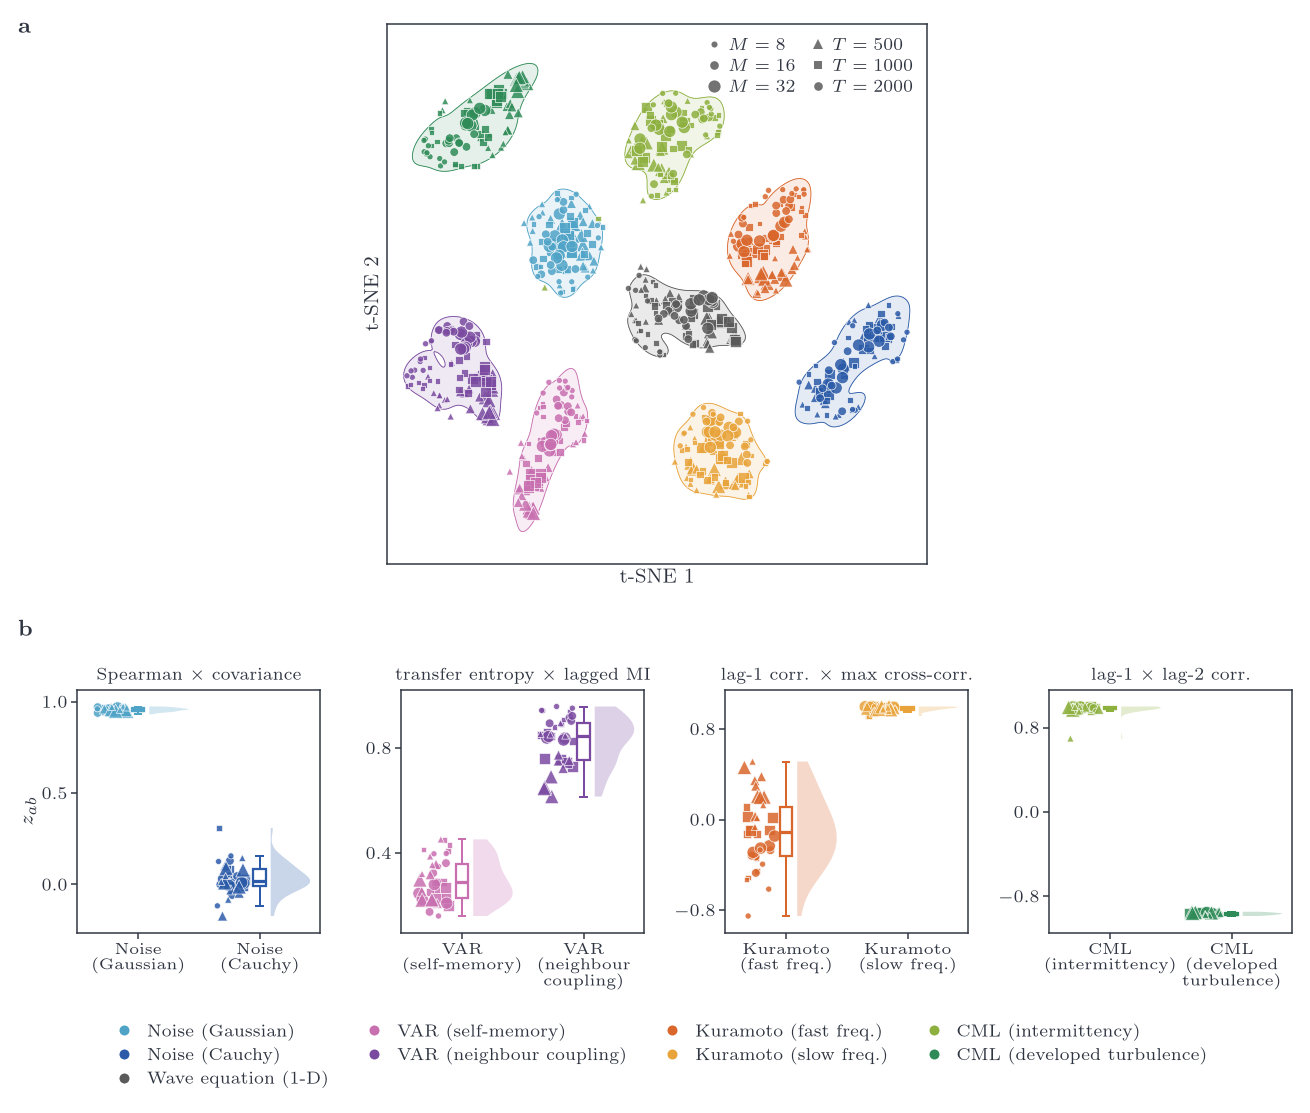

In [8]:
from research.proof.p90.proof_figure import load_config, fit_embedding, select_contrasts, plot_proof_figure
FIGURE = load_config()
figure_embedding = fit_embedding(bank, OUT, FIGURE)
contrasts = select_contrasts(bank, OUT, FIGURE)
print(f"PCA50 5NN accuracy, each M/T cell held out: {figure_embedding['audit']['pca50_knn5_cell_held_out_accuracy']:.3f}")
display(contrasts[['class_a', 'class_b', 'spi_a', 'spi_b', 'training_auc_oriented', 'display_auc_fixed_orientation']].round(3))
fig = plot_proof_figure(bank, figure_embedding, contrasts, FIGURE, OUT)
plt.show()

Contrast coordinates are fixed in the YAML. Each was chosen for how directly it maps onto the dynamics, from among coordinates whose training AUC is at least .995 in every M/T cell (instances 0–5). The rainclouds show instances 6–9. Many coordinates separate each pair, so these are illustrations, not unique or confirmatory axes.

- **Noise: Spearman versus covariance.** The channels are independent, so both statistics estimate zero. Under Gaussian tails their sampling errors co-vary across pairs. Cauchy outliers dominate the covariance and decouple it from the ranks.
- **VAR: transfer entropy versus lagged MI.** Transfer entropy is lagged MI conditioned on the target's own past ([Schreiber 2000](https://arxiv.org/abs/nlin/0001042)). With strong self-memory, much of the lagged dependence is inherited from each channel's own history, so the two statistics rank pairs differently. With neighbour coupling they agree.
- **Kuramoto: lag-1 Pearson versus the maximum cross-correlation over ±⌊T/4⌋ lags.** The maximum uses an amplitude cut of 1.96/√T, which is not a calibrated test. Fast oscillators complete about 1.5 cycles per record at T=500 and about 6 at T=2000, so fixed-lag correlation tracks phase offset while the lag search tracks alignment. Slow signals drift less than one cycle, and the two statistics agree. Fast-class values depend on T.
- **CML: lag-1 versus lag-2 Pearson.** In intermittency the laminar phases have period 3, so lags 1 and 2 are equivalent phase offsets and their correlation profiles match. Fully developed turbulence alternates with period 2 (simulated autocorrelation −.66 and +.47 at lags 1 and 2), so the sign flips between the two lags.


## What the ordered entries change

Same recordings, same preprocessing, two feature definitions. The rows report, per panel:
- coordinates and SPIs retained by the 95%-finite rule;
- PCA variance.

The last table compares the training-selected coordinates with those of the symmetrised 261015 view.

**Result.** The ordered entries add 13 SPIs to each panel: the antisymmetric phase, PSI, PLI/wPLI and group-delay statistics, which contribute nothing once symmetrised. The embeddings are refitted on the larger coordinate set. Every training-selected coordinate, and every composite coordinate, is unchanged with identical held-out AUC, because each pairs undirected SPIs.

In [9]:
import pandas as pd
from research.proof.p90.refresh_proof_figures import preprocess
legacy = load_bank(BANK, expected_spis=283)
protocol_exclude = ['frozen-chaos', 'fdstc']
panels = {'inter': ~np.isin(bank['y'], protocol_exclude), 'cml': np.isin(bank['y'], ['frozen-chaos', 'sti-i', 'defect-turbulence', 'fdstc'])}
rows = []
for label, b in [('symmetrised (261015)', legacy), ('ordered (261021)', bank)]:
    for panel, mask in panels.items():
        _, keep = preprocess(b['X'][mask])
        rows.append({'contract': label, 'panel': panel, 'coordinates': int(keep.sum()), 'SPIs': len(set(b['pairs'][keep].ravel()))})
display(pd.DataFrame(rows).pivot(index='panel', columns='contract', values=['coordinates', 'SPIs']))
changed = np.nanmax(np.abs(legacy['X'] - bank['X']), axis=0) > 1e-6
print(f"{changed.sum():,} of {changed.size:,} coordinates change value; all involve a directed SPI.")
old = pd.read_csv(ROOT / 'results/proof/viewer-261015/selected-features.csv')
cols = ['class_a', 'class_b', 'spi_a', 'spi_b', 'display_auc_fixed_orientation']
display(old[cols].merge(ranked[cols], on=['class_a', 'class_b'], suffixes=(' 261015', ' 261021')).round(3))

coordinates                                  SPIs  \
contract ordered (261021) symmetrised (261015) ordered (261021)   
panel                                                             
cml                 24751                23958              233   
inter               23641                22783              228   

                               
contract symmetrised (261015)  
panel                          
cml                       220  
inter                     215

20,805 of 39,903 coordinates change value; all involve a directed SPI.


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_65506/3893880874.py:12: RuntimeWarning: All-NaN slice encountered
  changed = np.nanmax(np.abs(legacy['X'] - bank['X']), axis=0) > 1e-6


,class_a,class_b,spi_a 261015,spi_b 261015,display_auc_fixed_orientation 261015,spi_a 261021,spi_b 261021,display_auc_fixed_orientation 261021
0,frozen-chaos,sti-i,cov_EmpiricalCovariance,corr_pearson_tau-2,1.000,cov_EmpiricalCovariance,corr_pearson_tau-2,1.000
1,frozen-chaos,defect-turbulence,cov_EmpiricalCovariance,prec_EmpiricalCovariance,0.999,cov_EmpiricalCovariance,prec_EmpiricalCovariance,0.999
2,frozen-chaos,fdstc,cov_EmpiricalCovariance,cov-sq_EllipticEnvelope,1.000,cov_EmpiricalCovariance,cov-sq_EllipticEnvelope,1.000
3,sti-i,defect-turbulence,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,0.972,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,0.972
4,sti-i,fdstc,cov_EmpiricalCovariance,prec-sq_EllipticEnvelope,1.000,cov_EmpiricalCovariance,prec-sq_EllipticEnvelope,1.000
5,defect-turbulence,fdstc,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,1.000,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,1.000
6,gaussian-noise,cauchy-noise,cov_EmpiricalCovariance,cov_EllipticEnvelope,1.000,cov_EmpiricalCovariance,cov_EllipticEnvelope,1.000
7,var-self-0.2_total-0.2,var-self-0.2_total-0.7,cov_EmpiricalCovariance,prec_OAS,1.000,cov_EmpiricalCovariance,prec_OAS,1.000
8,var-self-0.2_total-0.2,var-self-0.7_total-0.2,cov_EmpiricalCovariance,prec_OAS,1.000,cov_EmpiricalCovariance,prec_OAS,1.000
9,var-self-0.2_total-0.7,var-self-0.7_total-0.2,cov_EmpiricalCovariance,corr_pearson_tau-1,1.000,cov_EmpiricalCovariance,corr_pearson_tau-1,1.000
